In [43]:

# Step 1: Load the real UCI dataset

!pip -q install ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

# Download dataset
dataset = fetch_ucirepo(id=165)

X = dataset.data.features
y = dataset.data.targets

# Combine input features and target
df = pd.concat([X, y], axis=1)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())

print("\nMissing values:")
display(df.isnull().sum())


Dataset shape: (1030, 9)

Columns:
['Cement', 'Blast Furnace Slag', 'Fly Ash', 'Water', 'Superplasticizer', 'Coarse Aggregate', 'Fine Aggregate', 'Age', 'Concrete compressive strength']

First five records:


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30



Missing values:


,0
Cement,0
Blast Furnace Slag,0
Fly Ash,0
Water,0
Superplasticizer,0
Coarse Aggregate,0
Fine Aggregate,0
Age,0
Concrete compressive strength,0


In [44]:
# Display duplicated rows
duplicates = df[df.duplicated()]
display(duplicates)

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
77,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.40
80,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.40
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
100,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.20
103,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.20
109,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90
111,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90
123,425.0,106.3,0.0,153.5,16.5,852.1,887.1,28,60.29


In [45]:
# Remove duplicated rows
df = df.drop_duplicates()

# Reset row indices
df = df.reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicated rows:", df.duplicated().sum())


Dataset shape after removing duplicates: (1005, 9)
Remaining duplicated rows: 0


Exact duplicate records were identified and removed during preprocessing, reducing the dataset from 1,030 to 1,005 observations.

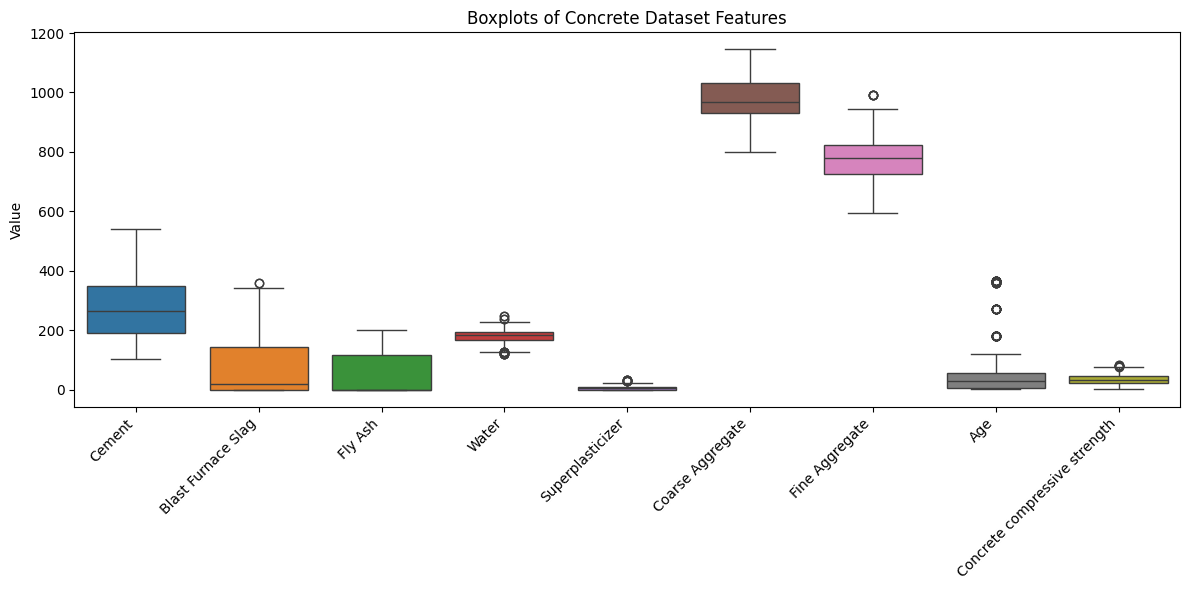

In [46]:

# Check potential outliers using boxplots

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.boxplot(data=df)

plt.xticks(rotation=45, ha="right")
plt.title("Boxplots of Concrete Dataset Features")
plt.ylabel("Value")

plt.tight_layout()
plt.show()


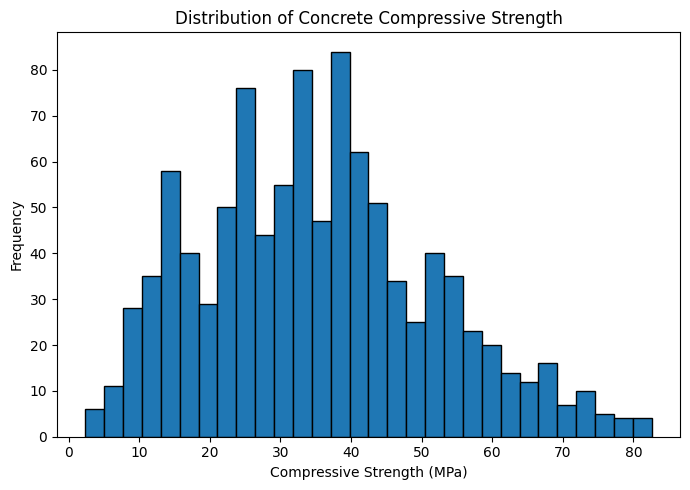

In [47]:

# Plot the distribution of compressive strength

target_column = df.columns[-1]

plt.figure(figsize=(7, 5))
plt.hist(df[target_column], bins=30, edgecolor="black")
plt.xlabel("Compressive Strength (MPa)")
plt.ylabel("Frequency")
plt.title("Distribution of Concrete Compressive Strength")
plt.tight_layout()
plt.show()



This hint shows the distrabution of our target column. It is seen that the

In [48]:

# Step 2: Correlation analysis
import seaborn as sns

# Calculate the correlation matrix
correlation_matrix = df.corr(method="pearson")

# Extract correlations with the target variable
target = "Concrete compressive strength"

target_correlation = correlation_matrix[target].sort_values(
    ascending=False
)

print("Correlation with compressive strength:")
display(target_correlation)


Correlation with compressive strength:


,Concrete compressive strength
Concrete compressive strength,1.000000
Cement,0.488283
Superplasticizer,0.344209
Age,0.337367
Blast Furnace Slag,0.103374
Fly Ash,-0.080648
Coarse Aggregate,-0.144717
Fine Aggregate,-0.186448
Water,-0.269624


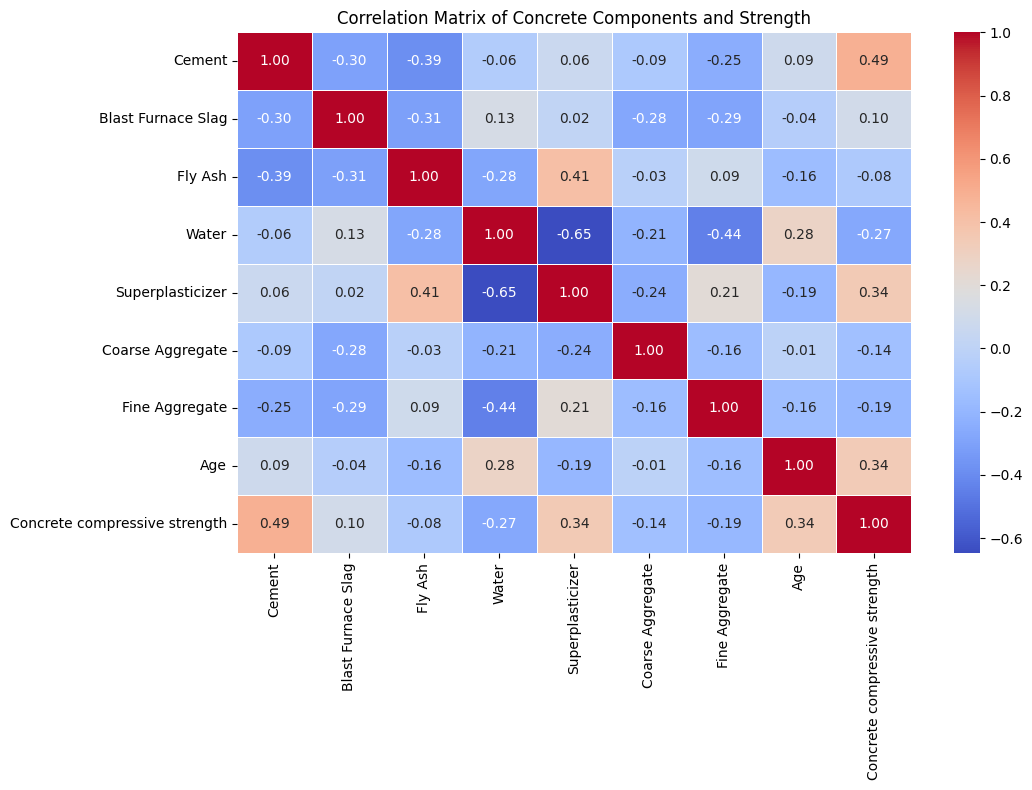

In [49]:

# Visualize the correlation matrix

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Concrete Components and Strength")
plt.tight_layout()
plt.show()


Pearson correlation analysis was performed to investigate the linear relationships between concrete mixture components and compressive strength.


Cement content showed the strongest positive linear correlation with compressive strength (r = 0.49), followed by superplasticizer content and curing age (both r = 0.34). Water content exhibited a negative correlation (r = -0.27). The correlations of blast furnace slag, fly ash, coarse aggregate, and fine aggregate with compressive strength were relatively weak in this dataset.




These results describe pairwise linear associations and do not establish causal relationships. Therefore, multivariable machine learning models will be developed to investigate the combined effects of mixture composition and curing age on compressive strength.

In [50]:

# Step 3: Split the dataset into training and testing sets

from sklearn.model_selection import train_test_split

# Define input features and target
X = df.drop(columns=["Concrete compressive strength"])
y = df["Concrete compressive strength"]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)


Training set size: (804, 8)
Testing set size: (201, 8)


In [51]:

# Step 4: Train machine learning models

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Model 1: Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Model 2: Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)
rf_model.fit(X_train, y_train)

print("Both models have been trained successfully!")


Both models have been trained successfully!


In [52]:

# Step 5: Evaluate model performance

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

models = {
    "Linear Regression": lr_model,
    "Random Forest": rf_model
}

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results)

display(results_df)


,Model,MAE,RMSE,R2
0,Linear Regression,8.895256,11.191320,0.580170
1,Random Forest,3.532900,5.203371,0.909243


In [53]:

# Step 6: 5-fold cross-validation

from sklearn.model_selection import KFold, cross_validate
from sklearn.ensemble import RandomForestRegressor

# Define cross-validation strategy
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define the model
rf_cv_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

# Evaluate using 5-fold cross-validation
cv_results = cross_validate(
    rf_cv_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "R2": "r2",
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error"
    }
)

# Convert negative error scores to positive values
cv_summary = pd.DataFrame({
    "R2": cv_results["test_R2"],
    "MAE": -cv_results["test_MAE"],
    "RMSE": -cv_results["test_RMSE"]
})

print("Cross-validation results for each fold:")
display(cv_summary)

print("\nAverage cross-validation performance:")
display(cv_summary.mean().to_frame(name="Mean"))


Cross-validation results for each fold:


,R2,MAE,RMSE
0,0.894380,3.723583,4.908553
1,0.883606,3.863402,5.289627
2,0.845256,4.393030,6.218125
3,0.896939,3.831146,5.426256
4,0.911928,3.536645,4.883628



Average cross-validation performance:


,Mean
R2,0.886422
MAE,3.869561
RMSE,5.345238


It is found that the Random Forest Regression substantially outperformed the linear regression baseline. Five-fold cross validation has the same outcome.The consistently strong performance across folds suggests that the Random Forest model captures nonlinear patterns in the dataset more effectively than the linear baseline.

Feature importance ranking:


,Feature,Importance
7,Age,0.357980
0,Cement,0.307231
3,Water,0.089717
4,Superplasticizer,0.081133
1,Blast Furnace Slag,0.075638
6,Fine Aggregate,0.045222
5,Coarse Aggregate,0.026855
2,Fly Ash,0.016225


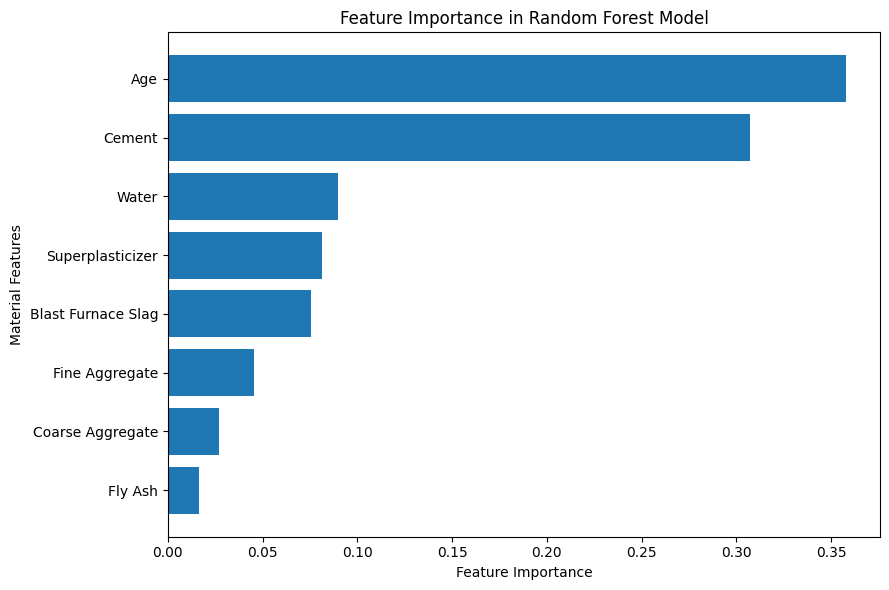

In [54]:

# Step 7: Feature importance analysis

# Get feature importance from the trained Random Forest model
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Feature importance ranking:")
display(feature_importance)

# Plot feature importance
plt.figure(figsize=(9, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Material Features")
plt.title("Feature Importance in Random Forest Model")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


Random Forest feature importance analysis identified curing age as the most influential predictive feature, followed by cement content. This ranking differs from the Pearson correlation analysis,

,Feature,Importance,Std
7,Age,0.740269,0.061061
0,Cement,0.593003,0.069735
1,Blast Furnace Slag,0.152403,0.017346
3,Water,0.111422,0.010778
4,Superplasticizer,0.107672,0.013926
6,Fine Aggregate,0.039841,0.004691
5,Coarse Aggregate,0.014903,0.003523
2,Fly Ash,0.007630,0.001168


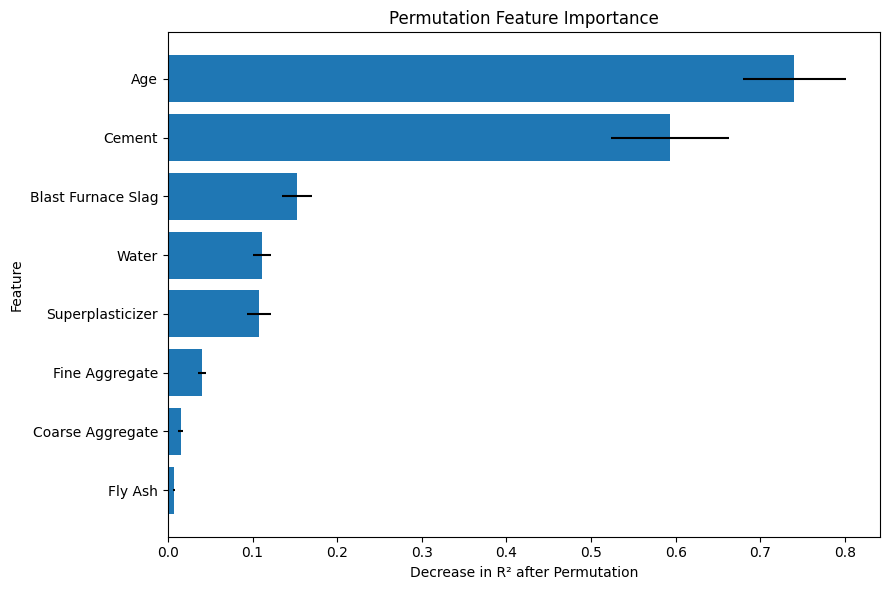

In [55]:

# Step 8: Permutation Feature Importance

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Calculate permutation importance on the test set
perm_result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="r2"
)

# Organize results
perm_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
})

# Sort by importance
perm_importance = perm_importance.sort_values(
    by="Importance",
    ascending=False
)

display(perm_importance)

# Visualize
plt.figure(figsize=(9, 6))

plt.barh(
    perm_importance["Feature"],
    perm_importance["Importance"],
    xerr=perm_importance["Std"]
)

plt.xlabel("Decrease in R² after Permutation")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


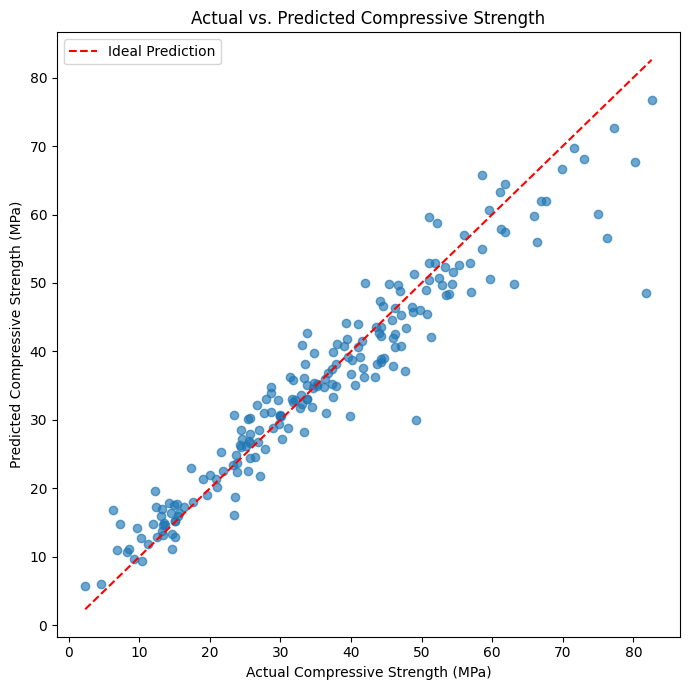

In [56]:

# Step 9: Actual vs. Predicted Values

import matplotlib.pyplot as plt
import numpy as np

# Generate predictions using the trained Random Forest model
y_pred = rf_model.predict(X_test)

# Plot actual vs predicted values
plt.figure(figsize=(7, 7))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.65
)

# Ideal prediction line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Ideal Prediction"
)

plt.xlabel("Actual Compressive Strength (MPa)")
plt.ylabel("Predicted Compressive Strength (MPa)")
plt.title("Actual vs. Predicted Compressive Strength")
plt.legend()
plt.tight_layout()
plt.show()


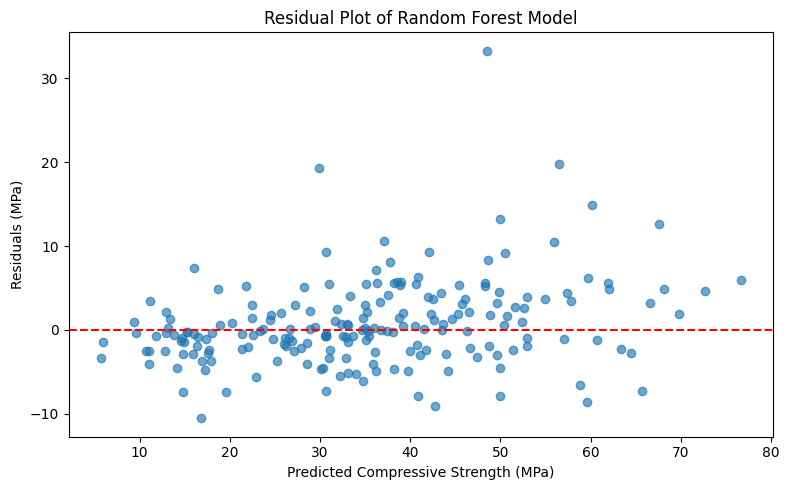

Mean residual: 0.7099636922530232
Residual standard deviation: 5.1675797553349545


In [57]:

# Step 10: Residual Analysis

residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.65
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted Compressive Strength (MPa)")
plt.ylabel("Residuals (MPa)")
plt.title("Residual Plot of Random Forest Model")

plt.tight_layout()
plt.show()

print("Mean residual:", residuals.mean())
print("Residual standard deviation:", residuals.std())


In [58]:

# Step 11: Identify the largest prediction errors

prediction_results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

prediction_results["Residual"] = (
    prediction_results["Actual"] -
    prediction_results["Predicted"]
)

prediction_results["Absolute Error"] = (
    prediction_results["Residual"].abs()
)

# Show the 10 samples with the largest errors
largest_errors = prediction_results.sort_values(
    by="Absolute Error",
    ascending=False
).head(10)

display(largest_errors)


,Actual,Predicted,Residual,Absolute Error
188,81.75,48.466100,33.283900,33.283900
56,76.24,56.496650,19.743350,19.743350
11,49.25,29.915150,19.334850,19.334850
48,74.99,60.143100,14.846900,14.846900
97,63.14,49.912950,13.227050,13.227050
187,80.20,67.622490,12.577510,12.577510
42,47.71,37.075833,10.634167,10.634167
130,6.27,16.816700,-10.546700,10.546700
114,66.42,55.994700,10.425300,10.425300
95,51.33,42.044800,9.285200,9.285200


The model showed larger prediction errors for some high-strength samples

In [59]:

# Step 12: Model-assisted candidate screening

# Use the held-out test set as candidate compositions
candidate_results = X_test.copy()

# Predict compressive strength
candidate_results["Predicted Strength (MPa)"] = rf_model.predict(X_test)

# Rank candidates by predicted strength
top_candidates = candidate_results.sort_values(
    by="Predicted Strength (MPa)",
    ascending=False
).head(10)

print("Top 10 candidate mixtures ranked by predicted strength:")
display(top_candidates)


Top 10 candidate mixtures ranked by predicted strength:


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Predicted Strength (MPa)
158,389.9,189.0,0.0,145.9,22.0,944.7,755.8,91,76.69825
136,362.6,189.0,0.0,164.9,11.6,944.7,755.8,56,72.67449
731,540.0,0.0,0.0,173.0,0.0,1125.0,613.0,180,69.77100
139,286.3,200.9,0.0,144.7,11.2,1004.6,803.7,56,68.13035
137,323.7,282.8,0.0,183.8,10.3,942.7,659.9,56,67.62249
381,500.0,0.0,0.0,151.0,9.0,1033.0,655.0,28,66.57810
377,475.0,0.0,0.0,162.0,9.5,1044.0,662.0,28,65.74970
110,425.0,106.3,0.0,151.4,18.6,936.0,803.7,28,64.51175
107,374.0,189.2,0.0,170.1,10.1,926.1,756.7,28,63.32615
334,277.2,97.8,24.5,160.7,11.2,1061.7,782.5,100,62.03795


In [60]:

# Step 13: Retrospective validation of selected candidates

# Match actual strengths using the original test-set indices
top_candidates["Actual Strength (MPa)"] = y_test.loc[
    top_candidates.index
]

top_candidates["Prediction Error (MPa)"] = (
    top_candidates["Actual Strength (MPa)"] -
    top_candidates["Predicted Strength (MPa)"]
)

display(top_candidates)


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Predicted Strength (MPa),Actual Strength (MPa),Prediction Error (MPa)
158,389.9,189.0,0.0,145.9,22.0,944.7,755.8,91,76.69825,82.60,5.90175
136,362.6,189.0,0.0,164.9,11.6,944.7,755.8,56,72.67449,77.30,4.62551
731,540.0,0.0,0.0,173.0,0.0,1125.0,613.0,180,69.77100,71.62,1.84900
139,286.3,200.9,0.0,144.7,11.2,1004.6,803.7,56,68.13035,72.99,4.85965
137,323.7,282.8,0.0,183.8,10.3,942.7,659.9,56,67.62249,80.20,12.57751
381,500.0,0.0,0.0,151.0,9.0,1033.0,655.0,28,66.57810,69.84,3.26190
377,475.0,0.0,0.0,162.0,9.5,1044.0,662.0,28,65.74970,58.52,-7.22970
110,425.0,106.3,0.0,151.4,18.6,936.0,803.7,28,64.51175,61.80,-2.71175
107,374.0,189.2,0.0,170.1,10.1,926.1,756.7,28,63.32615,61.09,-2.23615
334,277.2,97.8,24.5,160.7,11.2,1061.7,782.5,100,62.03795,66.95,4.91205


In [61]:

# Step 14: Evaluate the screening performance

# Actual top 10 samples in the test set
actual_top10 = y_test.nlargest(10)

# Predicted top 10 samples
predicted_top10_indices = top_candidates.index

# Actual strengths of model-selected candidates
selected_actual_strengths = y_test.loc[
    predicted_top10_indices
]

print(
    "Mean actual strength of model-selected candidates:",
    round(selected_actual_strengths.mean(), 2),
    "MPa"
)

print(
    "Mean actual strength of the actual top 10 candidates:",
    round(actual_top10.mean(), 2),
    "MPa"
)

print(
    "Overlap between predicted top 10 and actual top 10:",
    len(set(predicted_top10_indices) & set(actual_top10.index)),
    "/ 10"
)


Mean actual strength of model-selected candidates: 70.29 MPa
Mean actual strength of the actual top 10 candidates: 75.51 MPa
Overlap between predicted top 10 and actual top 10: 6 / 10


Among the ten highest-ranked candidates, the mean experimentally measured compressive strength was 70.29 MPa. Six of these candidates overlapped with the ten samples exhibiting the highest actual compressive strengths in the test set, corresponding to a top-10 overlap rate of 60%.

These results demonstrate the potential of Random Forest regression for preliminary screening of high-strength concrete mixtures. However, prediction errors remained substantial for some individual samples, particularly in the high-strength range.

In [62]:

# Additional validation: Group-based train-test split

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

# Group records by mixture composition
composition_columns = [
    "Cement",
    "Blast Furnace Slag",
    "Fly Ash",
    "Water",
    "Superplasticizer",
    "Coarse Aggregate",
    "Fine Aggregate"
]

groups = df[composition_columns].astype(str).agg(
    "_".join, axis=1
)

# Split by mixture composition
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(X, y, groups=groups)
)

X_train_group = X.iloc[train_idx]
X_test_group = X.iloc[test_idx]

y_train_group = y.iloc[train_idx]
y_test_group = y.iloc[test_idx]

# Train Random Forest
rf_group = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf_group.fit(X_train_group, y_train_group)

# Evaluate
group_pred = rf_group.predict(X_test_group)

print("Group-based test results")
print("Training samples:", len(train_idx))
print("Testing samples:", len(test_idx))

print("R2:", round(
    r2_score(y_test_group, group_pred), 4
))

print("MAE:", round(
    mean_absolute_error(y_test_group, group_pred), 4
))

print("RMSE:", round(
    np.sqrt(mean_squared_error(y_test_group, group_pred)), 4
))


Group-based test results
Training samples: 812
Testing samples: 193
R2: 0.8556
MAE: 4.4094
RMSE: 5.8346


In [63]:

# Verify that no exact mixture composition is shared
# between the group-based training and testing sets

train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])

overlap = train_groups.intersection(test_groups)

print("Number of overlapping compositions:", len(overlap))
print("Unique training compositions:", len(train_groups))
print("Unique testing compositions:", len(test_groups))


Number of overlapping compositions: 0
Unique training compositions: 341
Unique testing compositions: 86


To further investigate the model's ability to generalize to previously unseen mixture compositions, an additional group-based train-test split was performed.